# Time-Series Transformer for Electricity-Demand Forecasting

This notebook implements a clean basic Transformer for comparison with the LSTM model. It uses the same hourly electricity-demand series, chronological partitions, 168-hour input context and 96-hour forecasting horizon.

The model follows the main encoder-decoder idea used by Hertel et al. (2022), but it is intentionally smaller so that it can run on Google Colab or a normal local machine. This is a methodology-based reimplementation rather than an exact reproduction of the published experiment.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Install packages only if the Colab environment does not already have them.
# !pip install -q tensorflow pandas numpy scikit-learn matplotlib

from pathlib import Path
from time import perf_counter
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Add,
    Dense,
    Dropout,
    Input,
    Lambda,
    LayerNormalization,
    MultiHeadAttention,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Change this line only if the uploaded file has a different name.
DATA_PATH = Path('/content/drive/MyDrive/Research Trends /Implementation/electricity_processed_data/system_load_hourly.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/Research Trends /Implementation/electricity_processed_data')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONTEXT_HOURS = 168
DECODER_HISTORY_HOURS = 24
FORECAST_HOURS = 96
TRAIN_STRIDE = 1
EVALUATION_STRIDE = 96

TRAIN_END = pd.Timestamp('2013-12-31 23:00:00')
VALIDATION_START = pd.Timestamp('2014-01-01 00:00:00')
VALIDATION_END = pd.Timestamp('2014-06-30 23:00:00')
TEST_START = pd.Timestamp('2014-07-01 00:00:00')
TEST_END = pd.Timestamp('2014-12-31 23:00:00')

# Smaller than the published model so the experiment remains practical.
D_MODEL = 64
NUM_HEADS = 4
NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2
FEED_FORWARD_DIM = 128
DROPOUT_RATE = 0.10

print('TensorFlow version:', tf.__version__)
print('Data file:', DATA_PATH)

TensorFlow version: 2.21.0
Data file: /content/drive/MyDrive/Research Trends /Implementation/electricity_processed_data/system_load_hourly.csv


## 1. Load the hourly electricity-demand series

The CSV should contain a timestamp column and one hourly electricity-demand column. The loader recognises the common column names created during preprocessing.

In [3]:
if not DATA_PATH.exists():
    alternatives = [
        Path('/content/data/processed/system_load_hourly.csv'),
        Path('/content/hourly_demand.csv'),
        Path('/content/data/processed/hourly_demand.csv'),
    ]
    DATA_PATH = next((path for path in alternatives if path.exists()), DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        'Upload system_load_hourly.csv to /content, or update DATA_PATH.'
    )

data = pd.read_csv(DATA_PATH)

timestamp_candidates = ['timestamp', 'time', 'datetime', 'date']
timestamp_column = next(
    (column for column in timestamp_candidates if column in data.columns),
    data.columns[0],
)

target_candidates = [
    'total_load_kwh',
    'system_load_kwh',
    'hourly_demand_kwh',
    'demand_kwh',
    'demand',
]
target_column = next(
    (column for column in target_candidates if column in data.columns),
    None,
)

if target_column is None:
    numeric_columns = [
        column for column in data.columns
        if column != timestamp_column
        and pd.api.types.is_numeric_dtype(data[column])
    ]
    if len(numeric_columns) != 1:
        raise ValueError(
            'The demand column could not be identified. '
            f'Columns found: {data.columns.tolist()}'
        )
    target_column = numeric_columns[0]

series = data[[timestamp_column, target_column]].copy()
series[timestamp_column] = pd.to_datetime(series[timestamp_column], errors='coerce')
series[target_column] = pd.to_numeric(series[target_column], errors='coerce')
series = series.dropna().drop_duplicates(subset=timestamp_column)
series = series.sort_values(timestamp_column).set_index(timestamp_column)
series.columns = ['demand_kwh']
series.index.name = 'timestamp'

expected_index = pd.date_range(
    series.index.min(), series.index.max(), freq='1h', name='timestamp'
)

if not series.index.equals(expected_index):
    missing_hours = expected_index.difference(series.index)
    raise ValueError(
        f'The hourly timeline is incomplete. Missing hours: {len(missing_hours):,}'
    )

if series['demand_kwh'].isna().any():
    raise ValueError('Missing demand values remain in the dataset.')

if series['demand_kwh'].lt(0).any():
    raise ValueError('Negative demand values were found in the dataset.')

print(f'Rows: {len(series):,}')
print(f'Period: {series.index.min()} to {series.index.max()}')
display(series.head())
display(series.describe())

Rows: 26,304
Period: 2012-01-01 00:00:00 to 2014-12-31 23:00:00


,demand_kwh
timestamp,
2012-01-01 00:00:00,116562.32
2012-01-01 01:00:00,111071.97
2012-01-01 02:00:00,109904.79
2012-01-01 03:00:00,103967.57
2012-01-01 04:00:00,102113.58


,demand_kwh
count,26304.000000
mean,203225.628262
std,79698.779091
min,28046.318000
25%,126859.295000
50%,210220.385000
75%,249477.585000
max,445878.780000


## 2. Scale the data without leakage

The scaler is fitted using only the training period. The same training statistics are applied to the validation and test periods.

In [4]:
train_values = series.loc[:TRAIN_END, ['demand_kwh']].to_numpy(dtype=np.float32)

if len(train_values) == 0:
    raise ValueError('No observations were found in the training period.')

scaler = StandardScaler()
scaler.fit(train_values)

scaled_values = scaler.transform(
    series[['demand_kwh']].to_numpy(dtype=np.float32)
).astype(np.float32).reshape(-1)

with open(OUTPUT_DIR / 'scaler.json', 'w') as file:
    json.dump(
        {
            'mean': float(scaler.mean_[0]),
            'scale': float(scaler.scale_[0]),
            'fitted_until': str(TRAIN_END),
        },
        file,
        indent=2,
    )

print(f'Training mean: {scaler.mean_[0]:.4f} kWh')
print(f'Training standard deviation: {scaler.scale_[0]:.4f} kWh')

Training mean: 205781.5742 kWh
Training standard deviation: 80850.5316 kWh


## 3. Create the common forecasting windows

Every example contains 168 input hours and 96 target hours. The window rules are identical to the LSTM notebook.

In [5]:
def build_windows(values, index, target_start, target_end, stride):
    x_values, y_values, target_times = [], [], []
    last_start = len(values) - CONTEXT_HOURS - FORECAST_HOURS + 1

    for start in range(0, last_start, stride):
        target_position = start + CONTEXT_HOURS
        target_first_time = index[target_position]
        target_last_time = index[target_position + FORECAST_HOURS - 1]

        if target_first_time < target_start or target_last_time > target_end:
            continue

        x_values.append(values[start:target_position])
        y_values.append(values[target_position:target_position + FORECAST_HOURS])
        target_times.append(target_first_time)

    if not x_values:
        raise ValueError(f'No windows were created for {target_start} to {target_end}.')

    x_array = np.asarray(x_values, dtype=np.float32)[..., np.newaxis]
    y_array = np.asarray(y_values, dtype=np.float32)
    return x_array, y_array, pd.DatetimeIndex(target_times)


X_train, y_train, train_times = build_windows(
    scaled_values,
    series.index,
    series.index.min() + pd.Timedelta(hours=CONTEXT_HOURS),
    TRAIN_END,
    TRAIN_STRIDE,
)

X_validation, y_validation, validation_times = build_windows(
    scaled_values,
    series.index,
    VALIDATION_START,
    VALIDATION_END,
    EVALUATION_STRIDE,
)

X_test, y_test, test_times = build_windows(
    scaled_values,
    series.index,
    TEST_START,
    TEST_END,
    EVALUATION_STRIDE,
)

print('Training:', X_train.shape, y_train.shape)
print('Validation:', X_validation.shape, y_validation.shape)
print('Test:', X_test.shape, y_test.shape)

Training: (17281, 168, 1) (17281, 96)
Validation: (45, 168, 1) (45, 96)
Test: (45, 168, 1) (45, 96)


## 4. Build the basic encoder-decoder Transformer

The encoder receives the previous 168 demand values. The decoder receives the most recent 24 known values followed by 96 zeros for the unknown future period. Self-attention processes each sequence, while cross-attention allows the decoder to use the encoder output.

The published paper used a larger model. This reduced configuration keeps the central architecture while making the demonstration practical.

In [6]:
def positional_encoding(length, dimension):
    positions = np.arange(length)[:, np.newaxis]
    dimensions = np.arange(dimension)[np.newaxis, :]
    angle_rates = 1 / np.power(10000, (2 * (dimensions // 2)) / dimension)
    angles = positions * angle_rates
    encoding = np.zeros((length, dimension), dtype=np.float32)
    encoding[:, 0::2] = np.sin(angles[:, 0::2])
    encoding[:, 1::2] = np.cos(angles[:, 1::2])
    return tf.constant(encoding[np.newaxis, ...])


def encoder_block(inputs, layer_number):
    attention = MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=D_MODEL // NUM_HEADS,
        dropout=DROPOUT_RATE,
        name=f'encoder_attention_{layer_number}',
    )(inputs, inputs)
    x = LayerNormalization(epsilon=1e-6)(
        Add()([inputs, Dropout(DROPOUT_RATE)(attention)])
    )

    feed_forward = Dense(FEED_FORWARD_DIM, activation='relu')(x)
    feed_forward = Dense(D_MODEL)(feed_forward)
    return LayerNormalization(epsilon=1e-6)(
        Add()([x, Dropout(DROPOUT_RATE)(feed_forward)])
    )


def decoder_block(inputs, encoder_output, layer_number):
    masked_attention = MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=D_MODEL // NUM_HEADS,
        dropout=DROPOUT_RATE,
        name=f'decoder_masked_attention_{layer_number}',
    )(inputs, inputs, use_causal_mask=True)
    x = LayerNormalization(epsilon=1e-6)(
        Add()([inputs, Dropout(DROPOUT_RATE)(masked_attention)])
    )

    cross_attention = MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=D_MODEL // NUM_HEADS,
        dropout=DROPOUT_RATE,
        name=f'decoder_cross_attention_{layer_number}',
    )(x, encoder_output)
    x = LayerNormalization(epsilon=1e-6)(
        Add()([x, Dropout(DROPOUT_RATE)(cross_attention)])
    )

    feed_forward = Dense(FEED_FORWARD_DIM, activation='relu')(x)
    feed_forward = Dense(D_MODEL)(feed_forward)
    return LayerNormalization(epsilon=1e-6)(
        Add()([x, Dropout(DROPOUT_RATE)(feed_forward)])
    )


def build_transformer():
    encoder_input = Input(shape=(CONTEXT_HOURS, 1), name='encoder_input')

    encoder = Dense(D_MODEL, name='encoder_projection')(encoder_input)
    encoder = Lambda(
        lambda values: values + positional_encoding(CONTEXT_HOURS, D_MODEL),
        name='encoder_positional_encoding',
    )(encoder)

    for layer_number in range(NUM_ENCODER_LAYERS):
        encoder = encoder_block(encoder, layer_number + 1)

    decoder_length = DECODER_HISTORY_HOURS + FORECAST_HOURS
    decoder_input = Lambda(
        lambda values: tf.concat(
            [
                values[:, -DECODER_HISTORY_HOURS:, :],
                tf.zeros_like(values[:, :FORECAST_HOURS, :]),
            ],
            axis=1,
        ),
        name='prepare_decoder_input',
    )(encoder_input)

    decoder = Dense(D_MODEL, name='decoder_projection')(decoder_input)
    decoder = Lambda(
        lambda values: values + positional_encoding(decoder_length, D_MODEL),
        name='decoder_positional_encoding',
    )(decoder)

    for layer_number in range(NUM_DECODER_LAYERS):
        decoder = decoder_block(decoder, encoder, layer_number + 1)

    sequence_output = Dense(1, name='demand_output')(decoder)
    forecast = Lambda(
        lambda values: tf.squeeze(values[:, -FORECAST_HOURS:, :], axis=-1),
        name='forecast',
    )(sequence_output)

    return Model(encoder_input, forecast, name='BasicTimeSeriesTransformer')


tf.keras.backend.clear_session()
model = build_transformer()
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=5e-4),
    loss='mae',
    metrics=['mae'],
)
model.summary()

Model: "BasicTimeSeriesTransformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 168, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_projection  │ (None, 168, 64)   │        128 │ encoder_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_positional… │ (None, 168, 64)   │          0 │ encoder_projecti… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_attention_1 │ (None, 168, 64)   │     16,640 │ encoder_position… │
│ (MultiHeadAttentio… │                   │            │ encoder_position… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 168, 64)   │          0 │ encoder_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 168, 64)   │          0 │ encoder_position… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 168, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 168, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 168, 64)   │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 168, 64)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 168, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 168, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_attention_2 │ (None, 168, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 168, 64)   │          0 │ encoder_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prepare_decoder_in… │ (None, 120, 1)    │          0 │ encoder_input[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 168, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_projection  │ (None, 120, 64)   │        128 │ prepare_decoder_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 168, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 167,745 (655.25 KB)

 Trainable params: 167,745 (655.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the Transformer

Early stopping keeps the best validation weights and prevents unnecessary training.

In [7]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-5,
    ),
]

training_start = perf_counter()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=50,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)
training_seconds = perf_counter() - training_start

# Saving weights avoids custom-Lambda deserialisation problems.
model.save_weights(OUTPUT_DIR / 'transformer_168_to_96.weights.h5')
print(f'Training time: {training_seconds:.2f} seconds')

Epoch 1/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 78s 75ms/step - loss: 0.3606 - mae: 0.3606 - val_loss: 0.1203 - val_mae: 0.1203 - learning_rate: 5.0000e-04
Epoch 2/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.1559 - mae: 0.1559 - val_loss: 0.1045 - val_mae: 0.1045 - learning_rate: 5.0000e-04
Epoch 3/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.1419 - mae: 0.1419 - val_loss: 0.1020 - val_mae: 0.1020 - learning_rate: 5.0000e-04
Epoch 4/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.1347 - mae: 0.1347 - val_loss: 0.0975 - val_mae: 0.0975 - learning_rate: 5.0000e-04
Epoch 5/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - loss: 0.1302 - mae: 0.1302 - val_loss: 0.0937 - val_mae: 0.0937 - learning_rate: 5.0000e-04
Epoch 6/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.1269 - mae: 0.1269 - val_loss: 0.1005 - val_mae: 0.1005 - learning_rate: 5.0000e-04
Epoch 7/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.1250 - mae: 0.1250 - val_loss: 0.1017 - val_mae: 0.1

## 6. Evaluate the Transformer

Predictions are returned to kWh before MAE, RMSE and MAPE are calculated. The same previous-week seasonal baseline used by the LSTM is included.

In [8]:
prediction_start = perf_counter()
y_prediction_scaled = model.predict(X_test, batch_size=32, verbose=0)
inference_seconds = perf_counter() - prediction_start


def inverse_scale(values):
    original_shape = values.shape
    restored = scaler.inverse_transform(values.reshape(-1, 1))
    return restored.reshape(original_shape)


def safe_mape(actual, predicted):
    mask = np.abs(actual) > 1e-8
    return float(
        np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    )


y_actual = inverse_scale(y_test)
y_prediction = inverse_scale(y_prediction_scaled)

seasonal_scaled = X_test[:, :FORECAST_HOURS, 0]
seasonal_prediction = inverse_scale(seasonal_scaled)


def calculate_metrics(name, actual, predicted):
    return {
        'model': name,
        'MAE_kWh': mean_absolute_error(actual.ravel(), predicted.ravel()),
        'RMSE_kWh': np.sqrt(mean_squared_error(actual.ravel(), predicted.ravel())),
        'MAPE_percent': safe_mape(actual.ravel(), predicted.ravel()),
    }


metrics = pd.DataFrame([
    calculate_metrics('Seasonal naive', y_actual, seasonal_prediction),
    calculate_metrics('Transformer', y_actual, y_prediction),
])

metrics.loc[metrics['model'] == 'Transformer', 'training_seconds'] = training_seconds
metrics.loc[metrics['model'] == 'Transformer', 'inference_seconds'] = inference_seconds
metrics.loc[metrics['model'] == 'Transformer', 'parameters'] = model.count_params()

metrics.to_csv(OUTPUT_DIR / 'transformer_metrics.csv', index=False)
display(metrics.round(4))

,model,MAE_kWh,RMSE_kWh,MAPE_percent,training_seconds,inference_seconds,parameters
0,Seasonal naive,12760.5527,19800.3216,5.5454,NaN,NaN,NaN
1,Transformer,10199.0078,15736.4535,4.9266,185.4771,4.731,167745.0


## 7. Create report figures and prediction files

The forecast figure and metric table can be combined later with the LSTM results in the final comparison.

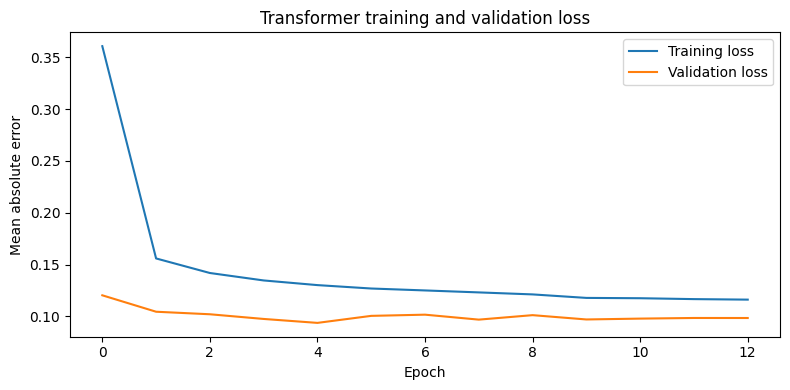

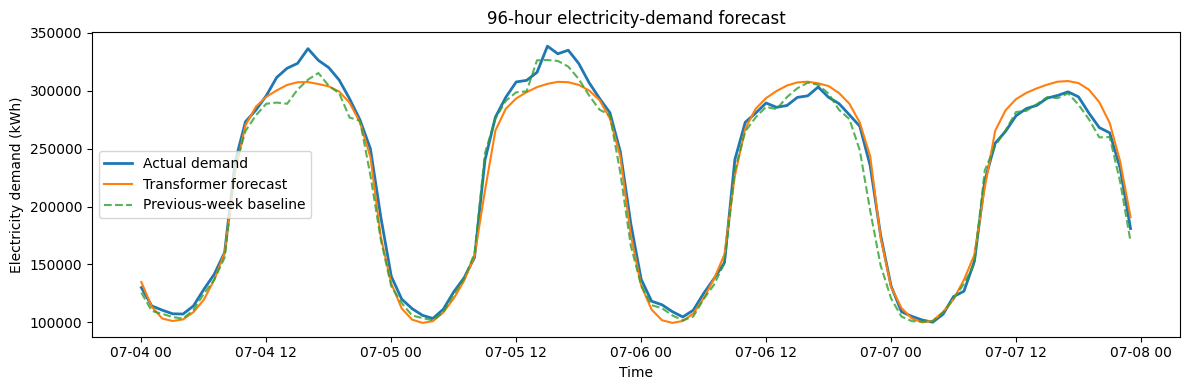

Saved files:
- .DS_Store
- client_metadata.csv
- experiment_details.json
- hourly_clients.parquet
- hourly_demand.csv
- scaler.json
- selected_clients.csv
- system_load_hourly.csv
- system_load_hourly.parquet
- test
- train
- transformer_168_to_96.weights.h5
- transformer_forecast_example.png
- transformer_loss_curve.png
- transformer_metrics.csv
- transformer_test_predictions.csv
- transformer_training_history.csv
- validation
- window_metadata.csv


In [9]:
history_frame = pd.DataFrame(history.history)
history_frame.to_csv(OUTPUT_DIR / 'transformer_training_history.csv', index=False)

plt.figure(figsize=(8, 4))
plt.plot(history_frame['loss'], label='Training loss')
plt.plot(history_frame['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Mean absolute error')
plt.title('Transformer training and validation loss')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'transformer_loss_curve.png', dpi=300)
plt.show()

window_number = 0
forecast_index = pd.date_range(
    test_times[window_number], periods=FORECAST_HOURS, freq='1h'
)

plt.figure(figsize=(12, 4))
plt.plot(forecast_index, y_actual[window_number], label='Actual demand', linewidth=2)
plt.plot(forecast_index, y_prediction[window_number], label='Transformer forecast')
plt.plot(
    forecast_index,
    seasonal_prediction[window_number],
    label='Previous-week baseline',
    linestyle='--',
    alpha=0.8,
)
plt.xlabel('Time')
plt.ylabel('Electricity demand (kWh)')
plt.title('96-hour electricity-demand forecast')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'transformer_forecast_example.png', dpi=300)
plt.show()

prediction_rows = []
for window_id, start_time in enumerate(test_times):
    timestamps = pd.date_range(start_time, periods=FORECAST_HOURS, freq='1h')
    for step, timestamp in enumerate(timestamps):
        prediction_rows.append({
            'window_id': window_id,
            'timestamp': timestamp,
            'actual_kwh': y_actual[window_id, step],
            'transformer_prediction_kwh': y_prediction[window_id, step],
            'seasonal_naive_kwh': seasonal_prediction[window_id, step],
        })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / 'transformer_test_predictions.csv', index=False
)

print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path.name)